In [1]:
import cvxpy as cp
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import yfinance as yf

In [2]:
tickers = ["AAPL", "AMZN", "COIN", "GOOG", "IBM", "META", "MSFT", "NVDA", "SPY", "TSLA"]

historical_prices = None

for t in tickers:
    ticker = yf.Ticker(t)
    history =  ticker.history(period="2y")

    monthly_prices = history['Close'].resample('ME').last()

    if historical_prices is None:
        historical_prices = monthly_prices
    else:
        historical_prices = pd.concat([historical_prices, monthly_prices], axis=1)

historical_prices.columns = tickers
historical_prices.index = pd.to_datetime(historical_prices.index).strftime("%Y-%m")

historical_prices

,AAPL,AMZN,COIN,GOOG,IBM,META,MSFT,NVDA,SPY,TSLA
Date,,,,,,,,,,
2024-08,227.100266,178.500000,183.360001,163.853241,191.595291,517.833862,411.425995,119.173569,550.644409,214.110001
2024-09,231.067093,186.330002,178.169998,166.135818,209.557632,569.165405,424.405670,121.250549,562.210388,261.630005
2024-10,224.035904,186.399994,179.250000,171.601151,195.946045,564.333252,400.783783,132.552872,557.193604,249.850006
2024-11,235.620087,207.889999,296.200012,169.415009,217.256546,571.034668,418.495392,138.034317,590.420837,345.160004
2024-12,248.615799,219.389999,248.300003,189.453918,210.014984,582.630249,416.558411,134.089737,576.215332,403.839996
2025-01,234.299683,237.679993,291.329987,204.535416,244.283447,685.790283,410.193878,119.890945,591.690369,404.600006
2025-02,240.361588,212.279999,215.619995,171.328278,242.775711,664.913452,393.122406,124.733704,584.178894,292.980011
2025-03,220.772079,190.259995,172.229996,155.598099,239.140427,574.035400,371.732880,108.228325,551.628906,259.160004
2025-04,211.200943,184.419998,202.889999,160.239273,232.562286,546.785767,391.409302,108.767563,546.846191,282.160004


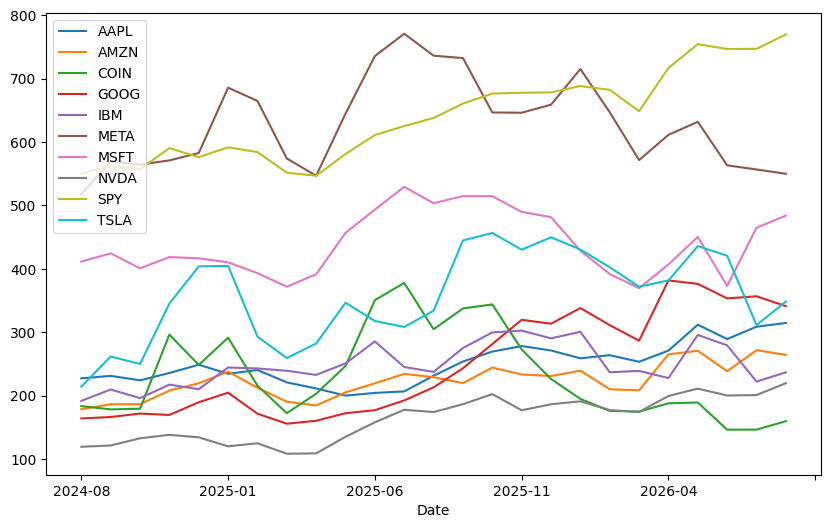

In [17]:
historical_prices.plot(figsize=(10, 6));

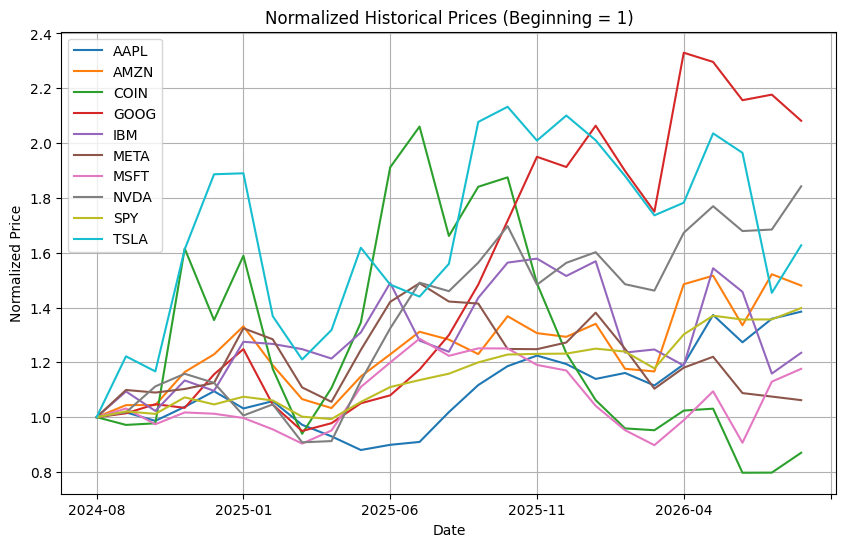

In [9]:
(historical_prices / historical_prices.iloc[0]).plot(figsize=(10, 6))
plt.title('Normalized Historical Prices (Beginning = 1)')
plt.ylabel('Normalized Price')
plt.grid(True)
plt.show()

In [3]:
historical_returns = historical_prices.pct_change().dropna()
estimated_returns = historical_returns.mean().rename("return")
estimated_returns.sort_values()

,return
META,0.006227
MSFT,0.010669
COIN,0.013856
SPY,0.014679
IBM,0.015361
AAPL,0.015455
AMZN,0.020519
NVDA,0.029752
TSLA,0.032537
GOOG,0.035906


/tmp/ipykernel_2648/3755339039.py:11: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  plt.annotate(ticker, (np.sqrt(estimated_variances[i]), estimated_returns[i]),


[]

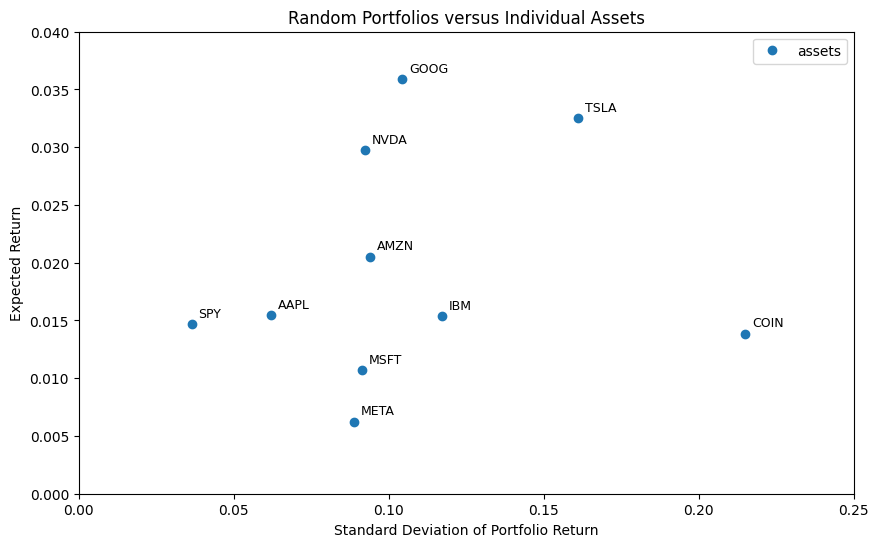

In [20]:
estimated_variances = historical_returns.var()

estimated_covariance = historical_returns.cov()

plt.figure(figsize=(10, 6))

plt.plot(np.sqrt(estimated_variances), estimated_returns, label="assets", linestyle="none", marker="o")

# Add labels to each asset point
for i, ticker in enumerate(tickers):
    plt.annotate(ticker, (np.sqrt(estimated_variances[i]), estimated_returns[i]),
                 xytext=(5, 5), textcoords='offset points', fontsize=9)

plt.legend()
plt.xlabel("Standard Deviation of Portfolio Return")
plt.xlim(0, 0.25)
plt.ylabel("Expected Return")
plt.ylim(0, 0.04)
plt.title("Random Portfolios versus Individual Assets")

plt.plot()

/tmp/ipykernel_2648/4277314171.py:19: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  plt.annotate(ticker, (np.sqrt(estimated_variances[i]), estimated_returns[i]),


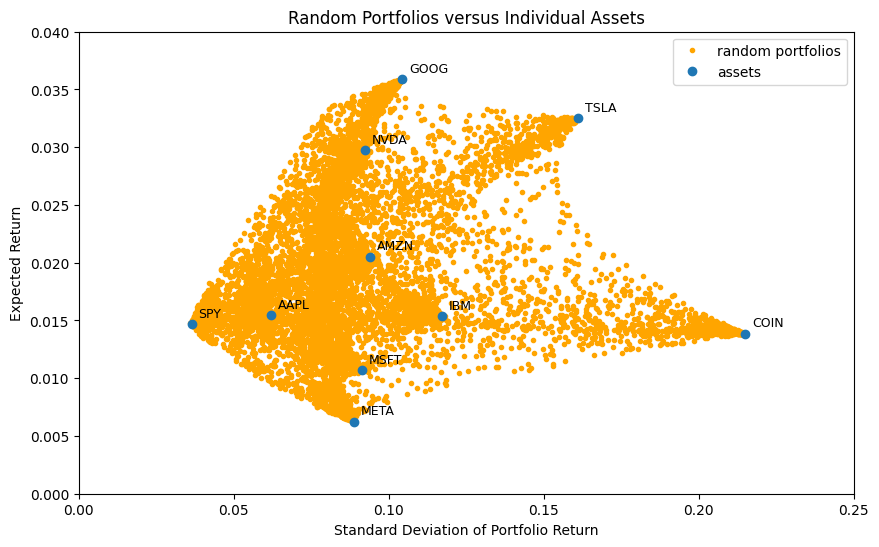

In [21]:
estimated_variances = historical_returns.var()

estimated_covariance = historical_returns.cov()

np.random.seed(704)
random_portfolios = np.random.geometric(0.01, size=(10000, len(tickers)))**5
random_portfolios = random_portfolios / random_portfolios.sum(axis=1)[:, None]

random_returns = random_portfolios @ estimated_returns
random_variances = [random_portfolios[i,:] @ estimated_covariance @ random_portfolios[i,:].T for i in range(len(random_portfolios))]

plt.figure(figsize=(10, 6))

plt.plot(np.sqrt(random_variances), random_returns, label="random portfolios", linestyle="none", marker=".", color="orange")
plt.plot(np.sqrt(estimated_variances), estimated_returns, label="assets", linestyle="none", marker="o")

# Add labels to each asset point
for i, ticker in enumerate(tickers):
    plt.annotate(ticker, (np.sqrt(estimated_variances[i]), estimated_returns[i]),
                 xytext=(5, 5), textcoords='offset points', fontsize=9)

plt.legend()
plt.xlabel("Standard Deviation of Portfolio Return")
plt.xlim(0, 0.25)
plt.ylabel("Expected Return")
plt.ylim(0, 0.04)

plt.title("Random Portfolios versus Individual Assets")

plt.show();

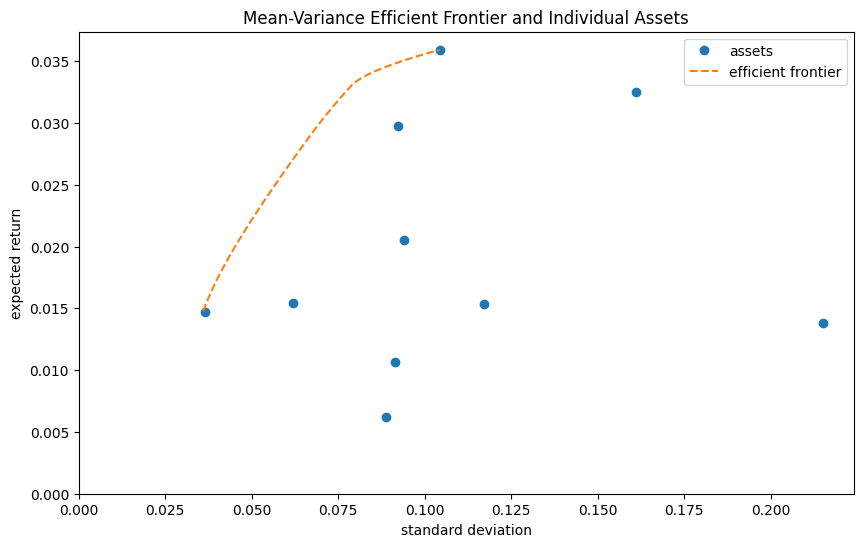

In [22]:
# minimum risk portfolio

n = len(estimated_returns)

x_minimum_risk = cp.Variable(n)

objective_minimum_risk = cp.Minimize(x_minimum_risk.T @ estimated_covariance.to_numpy() @ x_minimum_risk)
objective_minimum_risk

prob_minimum_risk = cp.Problem(objective_minimum_risk,
                               [0 <= x_minimum_risk,
                                cp.sum(x_minimum_risk) == 1])

covariance_minimum_risk = prob_minimum_risk.solve()
covariance_minimum_risk

estimated_return_minimum_risk = x_minimum_risk.value.T @ estimated_returns
estimated_return_minimum_risk

# maximum return portfolio

estimated_return_maximum_return = max(estimated_returns)

# efficient frontier

ef_variances = []
ef_returns = []
ef_portfolios = []

for r in np.linspace(estimated_return_minimum_risk, estimated_return_maximum_return, 1001):
    # create variables to optimize
    x_r = cp.Variable(n)

    # formulate linear program
    prob_r = cp.Problem(cp.Minimize(x_r.T @ estimated_covariance.to_numpy() @ x_r),
                        [0 <= x_r,
                         cp.sum(x_r) == 1,
                         x_r.T @ estimated_returns == r])
    ef_variances.append(prob_r.solve())
    ef_returns.append(r)
    ef_portfolios.append(x_r.value)

plt.figure(figsize=(10, 6))

plt.plot(np.sqrt(estimated_variances), estimated_returns, label="assets", linestyle="none", marker="o")
plt.plot(np.sqrt(ef_variances), ef_returns, label="efficient frontier", linestyle="--")

plt.legend()
plt.xlabel("standard deviation")
plt.xlim(0)
plt.ylabel("expected return")
plt.ylim(0)
plt.title("Mean-Variance Efficient Frontier and Individual Assets")
plt.show();

/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


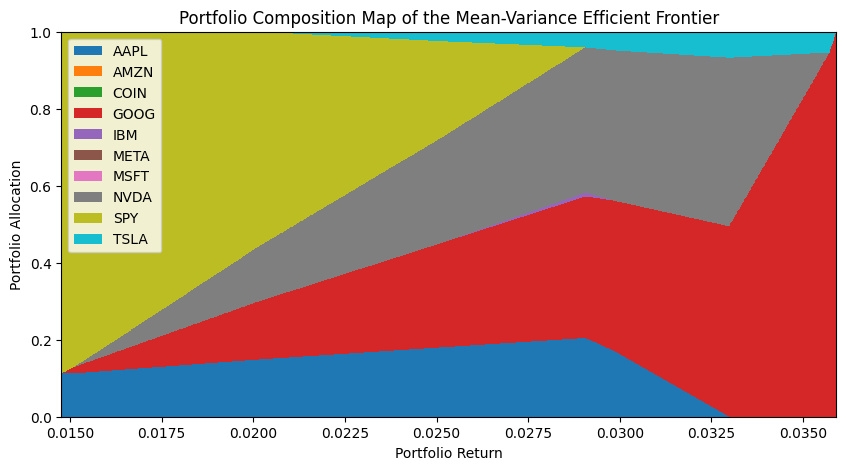

In [6]:
plt.figure(figsize=(10, 5))

ef_portfolios = np.asarray(ef_portfolios)
bottom = np.zeros(ef_portfolios.shape[0])
for (i, a) in enumerate(historical_returns.columns):
    plt.bar(x=ef_returns,
            height=ef_portfolios[:,i],
            bottom=bottom,
            label=a,
            width=(ef_returns[1] - ef_returns[0]))
    bottom += ef_portfolios[:,i]

plt.legend()
plt.xlabel("Portfolio Return")
plt.xlim(min(ef_returns), max(ef_returns))
plt.ylabel("Portfolio Allocation")
plt.ylim(0, 1)
plt.title("Portfolio Composition Map of the Mean-Variance Efficient Frontier")

plt.show();